# Unsupervised Learning: Mean Shift Clustering (UCI Wine Quality)

Notebook ini merupakan versi mandiri (*standalone*) dari pipeline **Unsupervised Learning (Mean Shift Clustering)** agar dapat dijalankan langsung secara terpisah di **Google Colab** maupun **Jupyter lokal** tanpa bergantung pada modul internal repositori.

### Apa yang dipelajari & dilakukan di notebook ini?
1. **Load & Validasi Dataset** (otomatis mendeteksi dataset lokal atau mengunduh dari UCI Machine Learning Repository jika dijalankan di Colab).
2. **Pemisahan Kolom Referensi (`quality`)**: kolom `quality` **dikecualikan** dari proses clustering agar algoritma murni mempelajari struktur fitur fisikokimia secara *unsupervised*, dan hanya dipakai sesudah clustering untuk melihat apakah kelompok kimia yang terbentuk berkorelasi dengan kualitas wine.
3. **Exploratory Data Analysis (EDA)**: statistik deskriptif dan heatmap korelasi.
4. **Preprocessing (`SimpleImputer` + `StandardScaler`)**: menyamakan skala seluruh fitur agar jarak Euclidean pada Mean Shift tidak didominasi fitur bernilai besar.
5. **Estimasi Bandwidth & Pelatihan Mean Shift**: menemukan jumlah cluster secara otomatis (*mode-seeking*).
6. **Evaluasi & Interpretasi**: Silhouette Score, Davies-Bouldin Index, ringkasan profil tiap cluster dalam satuan asli, proyeksi PCA 2D, distribusi ukuran cluster, heatmap profil pusat cluster, dan distribusi `quality` per cluster.
7. **Ekspor Artefak**: menyimpan model (`.joblib`), metrik (`metrics.json`), data hasil clustering (`clustered_wines.csv`), ringkasan cluster, dan grafik PNG.

## 1. Penjelasan Konsep Mean Shift Clustering

**Mean Shift** adalah algoritma clustering non-parametrik berbasis kepadatan (*density-based / mode-seeking*):
- Berbeda dengan **K-Means** yang mewajibkan kita menentukan jumlah cluster $K$ di awal, Mean Shift **menentukan jumlah cluster secara otomatis** dengan menggeser setiap titik menuju area dengan kerapatan data tertinggi (*mode* dari fungsi kepadatan kernel).
- **Parameter kunci — `bandwidth`**: menentukan radius jendela (*kernel window*) saat mencari puncak kepadatan.
  - `bandwidth` terlalu **kecil** → terlalu banyak cluster kecil / *singleton cluster* (berisi 1 data outlier).
  - `bandwidth` terlalu **besar** → hampir semua data menyatu ke 1 cluster raksasa.
  - Fungsi `estimate_bandwidth(..., quantile=...)` mengestimasi radius secara otomatis berdasarkan persentil jarak antar pasangan sampel.
- **`bin_seeding=True`**: mempercepat proses dengan memulai pencarian dari titik grid (*bin*), bukan dari setiap titik data satu per satu.
- **Mengapa `StandardScaler()` wajib?** Fitur seperti `total sulfur dioxide` berkisar puluhan hingga ratusan, sedangkan `chlorides` atau `density` berada di bawah `1`. Tanpa standardisasi, jarak Euclidean akan didominasi oleh fitur berskala besar.

In [1]:
# ==========================================
# 1. Import Library & Pengaturan Tampilan
# ==========================================
from datetime import datetime, timezone
import json
from pathlib import Path
from typing import Optional, Union
import urllib.request

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

print("Semua library berhasil dimuat.")

Semua library berhasil dimuat.


## 2. Konfigurasi Eksperimen

Ubah parameter di bawah ini untuk bereksperimen:
- `WINE_VARIANT`: `"white"` atau `"red"`.
- `CUSTOM_CSV_PATH`: path ke CSV sendiri jika ingin memakai dataset custom, atau `None`.
- `TARGET_REF`: kolom yang **dikecualikan** dari fitur clustering dan hanya dipakai sebagai referensi evaluasi pasca-clustering (default: `"quality"`).
- `BANDWIDTH`: isi angka positif (mis. `3.0`) untuk manual, atau `None` untuk estimasi otomatis memakai `estimate_bandwidth`.
- `QUANTILE`: rentang `(0, 1]` untuk `estimate_bandwidth` saat `BANDWIDTH=None` (default: `0.2`). Nilai lebih kecil menghasilkan lebih banyak cluster.
- `BANDWIDTH_SAMPLES`: jumlah sampel acak maksimum untuk estimasi bandwidth (default: `500`).
- `BIN_SEEDING`: `True` mempercepat komputasi Mean Shift (default: `True`).

In [2]:
# ==========================================
# 2. Konfigurasi Parameter Eksperimen
# ==========================================
WINE_VARIANT = "white"       # Pilihan: "white" atau "red"
CUSTOM_CSV_PATH = None       # Contoh di Colab: "/content/winequality-red.csv"
TARGET_REF = "quality"       # Dikecualikan dari fitur clustering!

BANDWIDTH = None             # Isi float > 0 jika ingin manual, atau None untuk otomatis
QUANTILE = 0.2               # Dipakai saat BANDWIDTH is None (0 < QUANTILE <= 1)
BANDWIDTH_SAMPLES = 500
RANDOM_STATE = 42
BIN_SEEDING = True

SAVE_ARTIFACTS = True
OUTPUT_DIR = Path("outputs/mean_shift")

if BANDWIDTH is not None and BANDWIDTH <= 0:
    raise ValueError("BANDWIDTH harus bernilai lebih besar dari 0.")
if not (0 < QUANTILE <= 1):
    raise ValueError("QUANTILE harus lebih besar dari 0 dan paling besar 1.")
if BANDWIDTH_SAMPLES < 1:
    raise ValueError("BANDWIDTH_SAMPLES harus minimal 1.")
if WINE_VARIANT not in {"white", "red"}:
    raise ValueError("WINE_VARIANT harus 'white' atau 'red'.")

## 3. Load & Validasi Dataset (Siap Jalan di Colab & Lokal)

Sama seperti notebook Supervised, sel ini mendeteksi file lokal terlebih dahulu dan otomatis mengunduh dari **UCI Machine Learning Repository** apabila dijalankan di **Google Colab**.
- Perhatikan bahwa `drop_missing_target=False` digunakan karena kolom `quality` tidak ikut dilatih (hanya referensi analisis setelah cluster terbentuk).

In [3]:
# ==========================================
# 3. Helper Download & Load Dataset Wine Quality
# ==========================================
UCI_URLS = {
    "white": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv",
    "red": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
}


def resolve_or_download_wine_csv(
    variant: str, custom_path: Optional[Union[str, Path]] = None
) -> Path:
    if custom_path is not None:
        path = Path(custom_path)
        if not path.is_file():
            raise FileNotFoundError(f"File custom tidak ditemukan: {path}")
        return path.resolve()

    filename = f"winequality-{variant}.csv"
    local_candidates = [
        Path("data/wine-quality") / filename,
        Path("../data/wine-quality") / filename,
        Path("wine+quality") / filename,
        Path("../wine+quality") / filename,
    ]
    for candidate in local_candidates:
        if candidate.is_file():
            print(f"Menggunakan dataset lokal: {candidate.resolve()}")
            return candidate.resolve()

    target_path = Path("data/wine-quality") / filename
    target_path.parent.mkdir(parents=True, exist_ok=True)
    url = UCI_URLS[variant]
    print(f"Dataset lokal tidak ditemukan. Mengunduh dari UCI Repository:\n{url}")
    urllib.request.urlretrieve(url, target_path)
    print(f"Dataset berhasil diunduh ke: {target_path.resolve()}")
    return target_path.resolve()


def load_wine_dataset(
    data_path: Path,
    target_column: str,
    *,
    drop_missing_target: bool = False,
    min_rows: int = 3,
) -> tuple:
    frame = pd.read_csv(data_path, sep=";")
    frame.columns = frame.columns.str.strip()

    if frame.empty:
        raise ValueError("Dataset kosong.")
    if target_column not in frame.columns:
        raise ValueError(
            f"Kolom referensi '{target_column}' tidak ditemukan. Kolom tersedia: {', '.join(frame.columns)}"
        )

    frame[target_column] = pd.to_numeric(frame[target_column], errors="coerce")
    if drop_missing_target:
        frame = frame.dropna(subset=[target_column]).copy()

    features = frame.drop(columns=target_column)
    non_numeric = features.select_dtypes(exclude=np.number).columns.tolist()
    if non_numeric:
        raise ValueError(f"Semua fitur harus numerik. Kolom non-numerik ditemukan: {', '.join(non_numeric)}")
    if features.shape[1] == 0:
        raise ValueError("Dataset tidak memiliki fitur untuk diproses.")
    if len(frame) < min_rows:
        raise ValueError(f"Dataset membutuhkan minimal {min_rows} baris valid.")

    return features, frame[target_column].rename(target_column)


data_path = resolve_or_download_wine_csv(WINE_VARIANT, CUSTOM_CSV_PATH)
features, reference = load_wine_dataset(data_path, TARGET_REF, drop_missing_target=False)

print(f"Jumlah sampel            : {len(features)}")
print(f"Jumlah fitur clustering  : {features.shape[1]} (kolom '{TARGET_REF}' dikecualikan)")
print(f"Fitur yang dipakai       : {list(features.columns)}")
display(features.head())

Menggunakan dataset lokal: /Users/muhammadwildan/Programming/kuliah/mechine-learning-project/data/wine-quality/winequality-white.csv
Jumlah sampel            : 4898
Jumlah fitur clustering  : 11 (kolom 'quality' dikecualikan)
Fitur yang dipakai       : ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9


## 4. Exploratory Data Analysis (EDA)

Kita memeriksa distribusi statistik fitur-fitur fisikokimia dan korelasinya satu sama lain sebelum dilakukan standardisasi dan clustering.

,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.8548,0.8439,3.8000,6.3000,6.8000,7.3000,14.200
volatile acidity,4898.0,0.2782,0.1008,0.0800,0.2100,0.2600,0.3200,1.100
citric acid,4898.0,0.3342,0.1210,0.0000,0.2700,0.3200,0.3900,1.660
residual sugar,4898.0,6.3914,5.0721,0.6000,1.7000,5.2000,9.9000,65.800
chlorides,4898.0,0.0458,0.0218,0.0090,0.0360,0.0430,0.0500,0.346
free sulfur dioxide,4898.0,35.3081,17.0071,2.0000,23.0000,34.0000,46.0000,289.000
total sulfur dioxide,4898.0,138.3607,42.4981,9.0000,108.0000,134.0000,167.0000,440.000
density,4898.0,0.9940,0.0030,0.9871,0.9917,0.9937,0.9961,1.039
pH,4898.0,3.1883,0.1510,2.7200,3.0900,3.1800,3.2800,3.820
sulphates,4898.0,0.4898,0.1141,0.2200,0.4100,0.4700,0.5500,1.080


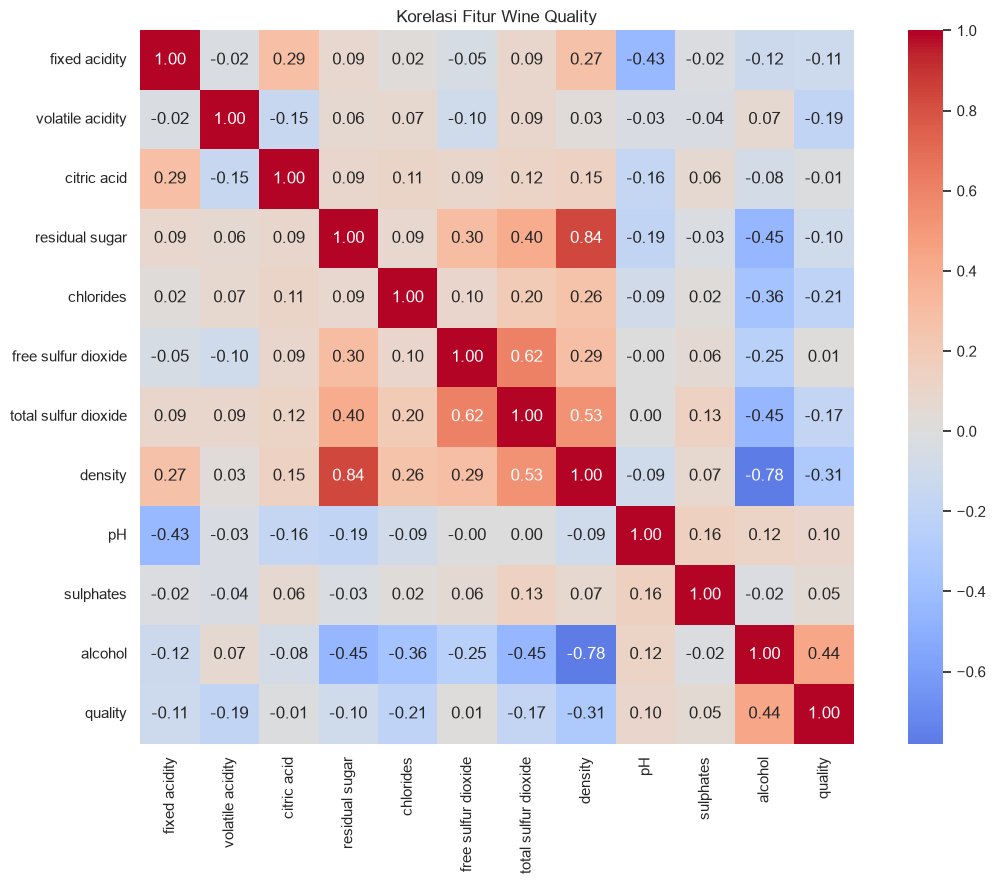

In [4]:
# ==========================================
# 4. EDA: Statistik Deskriptif & Matriks Korelasi
# ==========================================
if SAVE_ARTIFACTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

eda_frame = features.copy()
eda_frame[reference.name] = reference
eda_summary = eda_frame.describe().T

if SAVE_ARTIFACTS:
    eda_summary.to_csv(OUTPUT_DIR / "eda_summary.csv")

display(eda_summary)

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(eda_frame.corr(numeric_only=True), cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True, ax=ax)
ax.set_title("Korelasi Fitur Wine Quality")
fig.tight_layout()
if SAVE_ARTIFACTS:
    fig.savefig(OUTPUT_DIR / "correlation_matrix.png", dpi=160)
plt.show()

## 5. Preprocessing: Imputasi & Standardisasi Fitur

1. `SimpleImputer(strategy="median")` mengisi nilai kosong (jika ada).
2. `StandardScaler()` mengubah setiap fitur sehingga memiliki **mean = 0** dan **standar deviasi = 1**.
   - Langkah ini krusial untuk Mean Shift karena perhitungan jarak berbasis Euclidean dengan satu nilai `bandwidth` global untuk seluruh dimensi.

In [5]:
# ==========================================
# 5. Imputasi Median & StandardScaler
# ==========================================
imputer = SimpleImputer(strategy="median")
imputed_features = imputer.fit_transform(features)

scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_features)

scaled_preview = pd.DataFrame(scaled_features, columns=features.columns)
print("Ringkasan fitur setelah StandardScaler (mean ~ 0, std ~ 1):")
display(scaled_preview.describe().loc[["mean", "std", "min", "max"]].T)

Ringkasan fitur setelah StandardScaler (mean ~ 0, std ~ 1):


,mean,std,min,max
fixed acidity,-3.4816e-16,1.0001,-3.6204,8.7051
volatile acidity,4.4971e-16,1.0001,-1.9670,8.1536
citric acid,1.1605e-17,1.0001,-2.7617,10.9564
residual sugar,-1.0662e-16,1.0001,-1.1419,11.7141
chlorides,3.1335e-16,1.0001,-1.6833,13.7431
free sulfur dioxide,-1.0155e-17,1.0001,-1.9587,14.9183
total sulfur dioxide,-4.6422e-17,1.0001,-3.0442,7.0984
density,3.2472e-14,1.0001,-2.3130,15.0313
pH,-1.1838e-15,1.0001,-3.1014,4.1841
sulphates,-8.2181e-16,1.0001,-2.3647,5.1716


## 6. Estimasi Bandwidth & Pelatihan Mean Shift

- Jika `BANDWIDTH=None`, `estimate_bandwidth` menghitung jarak antar pasangan sampel (maksimal `BANDWIDTH_SAMPLES` titik) dan mengambil kuantil ke-`QUANTILE`.
- Selanjutnya `MeanShift(bandwidth=..., bin_seeding=..., cluster_all=True, n_jobs=-1)` mengelompokkan seluruh data (`cluster_all=True` memastikan setiap titik tetap mendapat label cluster terdekat meskipun berada di tepi kepadatan).

In [6]:
# ==========================================
# 6. Resolusi Bandwidth & Fit Mean Shift
# ==========================================
if BANDWIDTH is not None:
    resolved_bandwidth = float(BANDWIDTH)
    bandwidth_source = "manual"
else:
    resolved_bandwidth = float(
        estimate_bandwidth(
            scaled_features,
            quantile=QUANTILE,
            n_samples=min(BANDWIDTH_SAMPLES, len(scaled_features)),
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    )
    bandwidth_source = "estimated"
    if not np.isfinite(resolved_bandwidth) or resolved_bandwidth <= 0:
        raise ValueError("Estimasi bandwidth tidak valid. Set nilai BANDWIDTH positif secara manual.")

clusterer = MeanShift(
    bandwidth=resolved_bandwidth,
    bin_seeding=BIN_SEEDING,
    cluster_all=True,
    n_jobs=-1,
)
labels = clusterer.fit_predict(scaled_features)

label_values, label_counts = np.unique(labels, return_counts=True)
singleton_count = int(np.sum(label_counts == 1))

print(f"Bandwidth ({bandwidth_source}) : {resolved_bandwidth:.4f}")
print(f"Jumlah cluster terbentuk : {len(label_values)}")
print(f"Cluster terbesar         : {int(label_counts.max())} sampel ({label_counts.max() / len(labels) * 100:.2f}%)")
print(f"Singleton cluster (1 dt) : {singleton_count}")

Bandwidth (estimated) : 3.4617
Jumlah cluster terbentuk : 14
Cluster terbesar         : 4672 sampel (95.39%)
Singleton cluster (1 dt) : 4


## 7. Evaluasi Clustering & Ringkasan Profil Cluster

Karena tidak ada label kebenaran (*ground truth*) saat pelatihan, kualitas cluster dievaluasi menggunakan **metrik internal** pada fitur terstandarisasi:
- **Silhouette Score** (`-1` hingga `+1`): mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibanding cluster tetangga terdekat. Nilai mendekati `+1` berarti cluster padat dan terpisah baik; nilai dekat `0` berarti banyak tumpang tindih.
- **Davies-Bouldin Index** (`>= 0`): rasio antara sebaran dalam cluster dan jarak antar pusat cluster. **Semakin kecil (mendekati 0) semakin baik**.
- **Catatan Singleton Cluster**: Mean Shift sensitif terhadap pencilan (*outlier*) sehingga sering membentuk beberapa cluster kecil berisi 1 data (*singleton*). Hal ini wajar secara matematis, namun metrik seperti Silhouette/DBI perlu diinterpretasikan dengan hati-hati saat terdapat banyak singleton atau satu cluster dominan.

In [7]:
# ==========================================
# 7. Metrik Evaluasi & Tabel Ringkasan Cluster
# ==========================================
cluster_count = int(len(label_values))
if 2 <= cluster_count < len(scaled_features):
    silhouette = float(silhouette_score(scaled_features, labels))
    davies_bouldin = float(davies_bouldin_score(scaled_features, labels))
    eval_note = "Metrik dihitung pada fitur yang telah distandarisasi."
    if singleton_count:
        eval_note += f" Terdapat {singleton_count} cluster berisi satu data; interpretasikan metrik dengan hati-hati."
else:
    silhouette = None
    davies_bouldin = None
    eval_note = "Silhouette Score dan Davies-Bouldin Index tidak dihitung karena jumlah/ukuran cluster tidak memenuhi syarat."

metrics = {
    "dataset": str(data_path),
    "excluded_target": TARGET_REF,
    "feature_count": int(features.shape[1]),
    "sample_count": int(len(features)),
    "cluster_count": cluster_count,
    "largest_cluster_samples": int(label_counts.max()),
    "largest_cluster_percentage": float(label_counts.max() / len(labels) * 100),
    "singleton_cluster_count": singleton_count,
    "bandwidth": resolved_bandwidth,
    "bandwidth_source": bandwidth_source,
    "bin_seeding": BIN_SEEDING,
    "silhouette_score": silhouette,
    "davies_bouldin_index": davies_bouldin,
    "evaluation_note": eval_note,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
}
print(json.dumps(metrics, indent=2))

# Bangun ringkasan rata-rata fitur per cluster dalam satuan asli
clustered_df = features.copy()
clustered_df[reference.name] = reference
clustered_df["cluster"] = labels

aggregation = {
    "sample_count": ("cluster", "size"),
    f"mean_{reference.name}": (reference.name, "mean"),
}
aggregation.update({f"mean_{col}": (col, "mean") for col in features.columns})

summary = clustered_df.groupby("cluster", sort=True).agg(**aggregation).reset_index()
summary["percentage"] = summary["sample_count"] / len(clustered_df) * 100
summary = summary.sort_values("sample_count", ascending=False)

original_centers = scaler.inverse_transform(clusterer.cluster_centers_)
centers_df = pd.DataFrame(original_centers, columns=features.columns).assign(cluster=label_values)

if SAVE_ARTIFACTS:
    summary.to_csv(OUTPUT_DIR / "cluster_summary.csv", index=False)
    clustered_df.to_csv(OUTPUT_DIR / "clustered_wines.csv", index=False)
    centers_df.to_csv(OUTPUT_DIR / "cluster_centers.csv", index=False)
    with (OUTPUT_DIR / "metrics.json").open("w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2)

print("\nRingkasan Profil Cluster (satuan asli, diurutkan dari cluster terbesar):")
display(summary)

{
  "dataset": "/Users/muhammadwildan/Programming/kuliah/mechine-learning-project/data/wine-quality/winequality-white.csv",
  "excluded_target": "quality",
  "feature_count": 11,
  "sample_count": 4898,
  "cluster_count": 14,
  "largest_cluster_samples": 4672,
  "largest_cluster_percentage": 95.3858717844018,
  "singleton_cluster_count": 4,
  "bandwidth": 3.461712712197264,
  "bandwidth_source": "estimated",
  "bin_seeding": true,
  "silhouette_score": 0.1663178192422381,
  "davies_bouldin_index": 1.3062034231931443,
  "evaluation_note": "Metrik dihitung pada fitur yang telah distandarisasi. Terdapat 4 cluster berisi satu data; interpretasikan metrik dengan hati-hati.",
  "created_at_utc": "2026-11-18T11:41:54.055016+00:00"
}

Ringkasan Profil Cluster (satuan asli, diurutkan dari cluster terbesar):


,cluster,sample_count,mean_quality,mean_fixed acidity,mean_volatile acidity,mean_citric acid,mean_residual sugar,mean_chlorides,mean_free sulfur dioxide,mean_total sulfur dioxide,mean_density,mean_pH,mean_sulphates,mean_alcohol,percentage
0,0,4672,5.9052,6.8170,0.2740,0.3278,6.2532,0.0437,34.7562,136.7920,0.9939,3.1940,0.4896,10.5528,95.3859
6,6,39,5.1795,8.7308,0.4458,0.3105,5.0859,0.0546,18.5128,111.0000,0.9945,2.9497,0.4492,10.1103,0.7962
1,1,37,5.3784,6.8730,0.3630,0.4451,5.4122,0.2013,38.6892,157.5405,0.9951,3.0627,0.4941,9.4162,0.7554
3,3,36,5.3611,7.5722,0.3337,0.7842,13.5194,0.0458,46.0000,180.0278,0.9979,3.0989,0.5114,9.6861,0.7350
8,8,26,5.4615,8.3731,0.3246,0.4450,12.3538,0.0540,48.7692,242.6346,0.9989,3.0635,0.6408,9.2192,0.5308
13,13,25,5.5200,6.5800,0.2622,0.5432,3.8200,0.1604,46.4400,128.4400,0.9937,3.1056,0.4216,9.8000,0.5104
7,7,24,5.3333,7.2542,0.2619,0.3017,8.1292,0.0457,104.7292,212.8750,0.9957,3.1171,0.4775,9.8958,0.4900
4,4,20,5.5000,7.3450,0.3213,0.3725,24.1850,0.0530,43.7000,184.3000,1.0040,3.0575,0.4640,9.1800,0.4083
2,2,13,4.6154,7.8308,0.8219,0.3354,6.2385,0.0462,33.1538,178.3846,0.9957,3.1831,0.4969,10.2231,0.2654
5,5,2,4.5000,13.0000,0.2500,0.4350,6.1000,0.0355,24.0000,139.5000,0.9959,3.0400,0.5450,10.4000,0.0408


## 8. Visualisasi Hasil Mean Shift Clustering

Lima grafik berikut membantu memahami struktur cluster yang terbentuk:
1. **Visualisasi PCA 2D (`clusters_pca.png`)**: memproyeksikan 11 fitur terstandarisasi ke 2 komponen utama PCA beserta tanda `X` sebagai pusat masing-masing cluster.
2. **Distribusi Ukuran Cluster (`cluster_size_distribution.png`)**: memakai skala logaritmik pada sumbu Y agar cluster kecil/outlier tetap terlihat di samping cluster mayoritas.
3. **Profil Pusat Cluster (`cluster_profile_heatmap.png`)**: menampilkan posisi pusat cluster dalam skala Z-score; warna merah tua/biru tua menunjukkan fitur yang menjadi pembeda ekstrem suatu cluster (misal cluster dengan `residual sugar` atau `chlorides` sangat tinggi).
4. **Distribusi & Rata-rata `quality` per Cluster**: mengecek apakah kelompok kimia yang ditemukan secara *unsupervised* berkorespondensi dengan perbedaan skor `quality`.

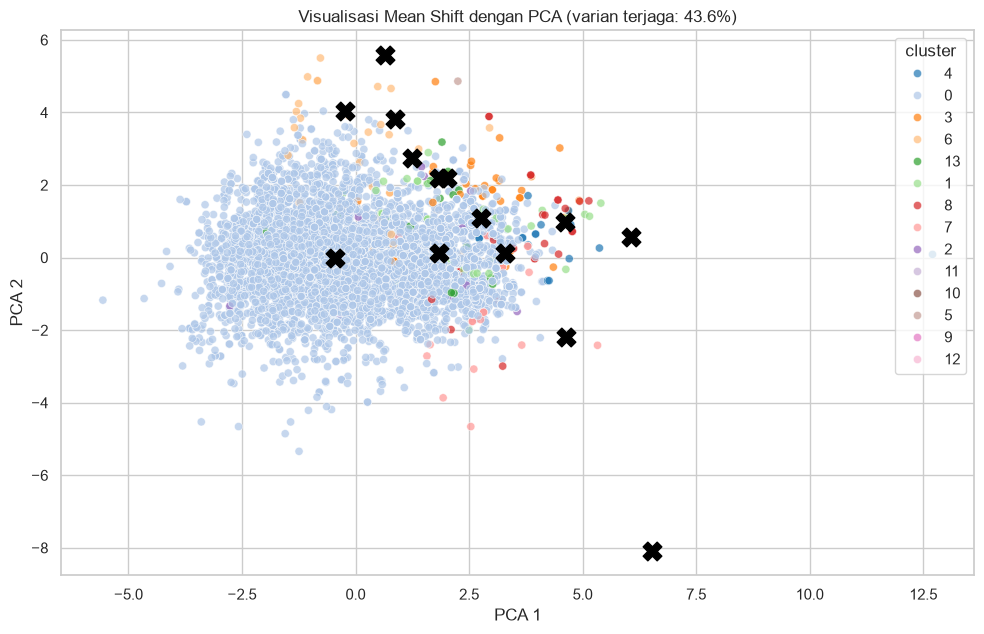

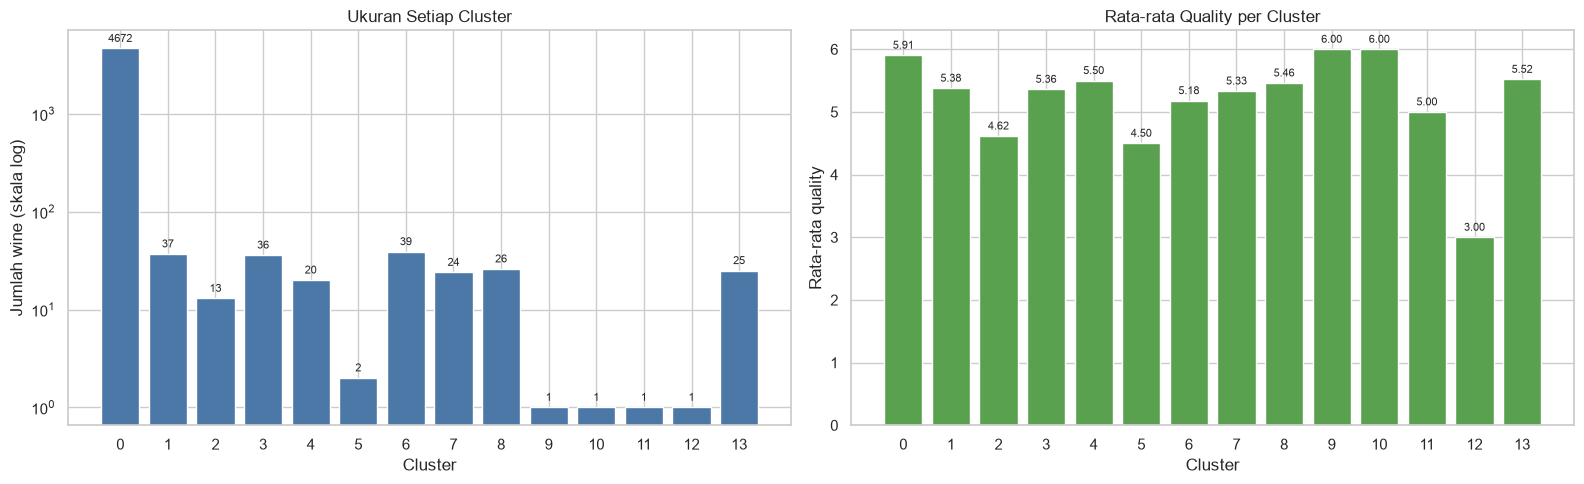

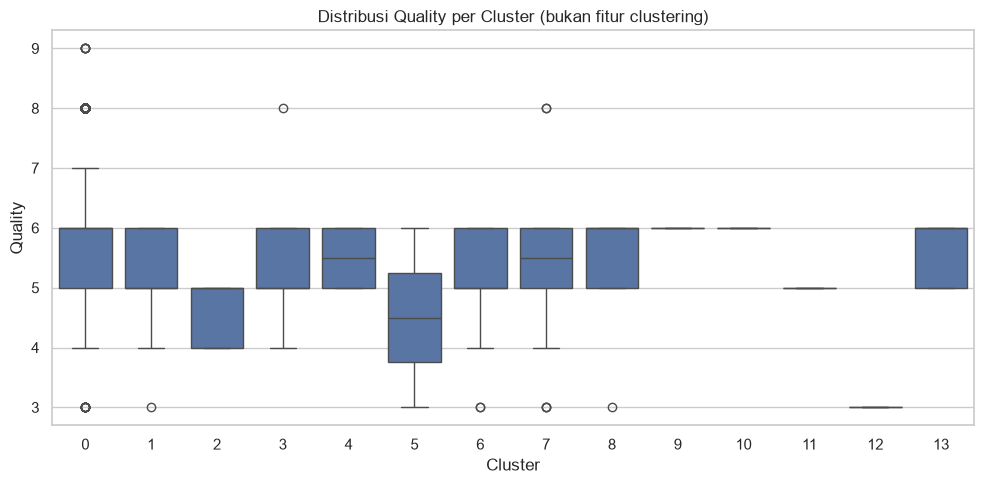

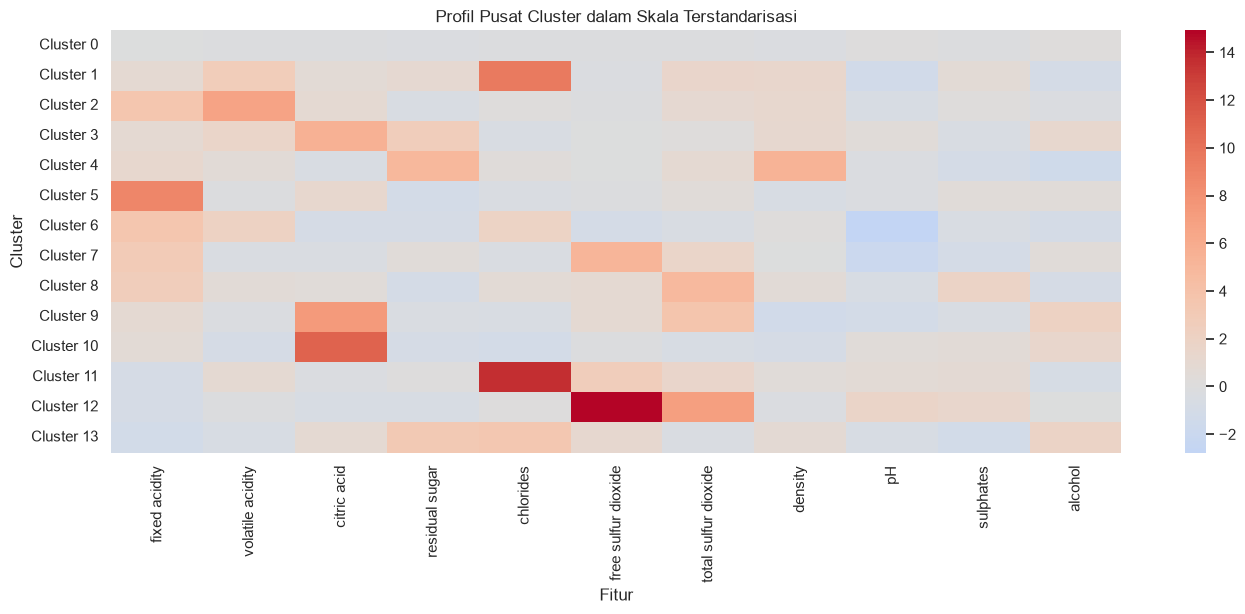

Semua artefak clustering berhasil disimpan di: /Users/muhammadwildan/Programming/kuliah/mechine-learning-project/notebook/outputs/mean_shift


In [8]:
# ==========================================
# 8. Plot Visualisasi Cluster & Simpan Artefak
# ==========================================
# 1. PCA 2D Scatter Plot
pca = PCA(n_components=min(2, scaled_features.shape[1]))
reduced_features = pca.fit_transform(scaled_features)
reduced_centers = pca.transform(clusterer.cluster_centers_)

if reduced_features.shape[1] >= 2:
    plot_frame = pd.DataFrame(
        {
            "PCA 1": reduced_features[:, 0],
            "PCA 2": reduced_features[:, 1],
            "cluster": labels.astype(str),
        }
    )
    fig, ax = plt.subplots(figsize=(10, 6.5))
    sns.scatterplot(
        data=plot_frame,
        x="PCA 1",
        y="PCA 2",
        hue="cluster",
        palette="tab20",
        alpha=0.7,
        s=35,
        ax=ax,
    )
    ax.scatter(
        reduced_centers[:, 0],
        reduced_centers[:, 1],
        marker="X",
        s=180,
        color="black",
        label="Pusat cluster",
        zorder=3,
    )
    explained = pca.explained_variance_ratio_.sum() * 100
    ax.set_title(f"Visualisasi Mean Shift dengan PCA (varian terjaga: {explained:.1f}%)")
    fig.tight_layout()
    if SAVE_ARTIFACTS:
        fig.savefig(OUTPUT_DIR / "clusters_pca.png", dpi=160)
    plt.show()

# 2. Ukuran Cluster (skala log) & Rata-rata Quality per Cluster
plot_summary = summary.sort_values("cluster")
cluster_labels_str = plot_summary["cluster"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

bars_size = axes[0].bar(cluster_labels_str, plot_summary["sample_count"], color="#4C78A8")
axes[0].bar_label(bars_size, padding=3, fontsize=8)
axes[0].set_yscale("log")
axes[0].set(xlabel="Cluster", ylabel="Jumlah wine (skala log)", title="Ukuran Setiap Cluster")

mean_q_col = f"mean_{reference.name}"
bars_q = axes[1].bar(cluster_labels_str, plot_summary[mean_q_col], color="#59A14F")
axes[1].bar_label(bars_q, fmt="%.2f", padding=3, fontsize=8)
axes[1].set(xlabel="Cluster", ylabel=f"Rata-rata {reference.name}", title="Rata-rata Quality per Cluster")

fig.tight_layout()
plt.show()

if SAVE_ARTIFACTS:
    for fname, col, ylabel, title, color, is_log, fmt in [
        ("cluster_size_distribution.png", "sample_count", "Jumlah wine (skala log)", "Ukuran Setiap Cluster", "#4C78A8", True, None),
        ("mean_quality_by_cluster.png", mean_q_col, f"Rata-rata {reference.name}", "Rata-rata Quality per Cluster", "#59A14F", False, "%.2f"),
    ]:
        f_s, a_s = plt.subplots(figsize=(10, 5))
        b = a_s.bar(cluster_labels_str, plot_summary[col], color=color)
        a_s.bar_label(b, fmt=fmt, padding=3, fontsize=8) if fmt else a_s.bar_label(b, padding=3, fontsize=8)
        if is_log:
            a_s.set_yscale("log")
        a_s.set(xlabel="Cluster", ylabel=ylabel, title=title)
        f_s.tight_layout()
        f_s.savefig(OUTPUT_DIR / fname, dpi=160)
        plt.close(f_s)

# 3. Boxplot Quality per Cluster
quality_frame = pd.DataFrame({"cluster": labels.astype(str), reference.name: reference})
order_clusters = [str(c) for c in sorted(label_values)]
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=quality_frame, x="cluster", y=reference.name, order=order_clusters, ax=ax)
ax.set_title("Distribusi Quality per Cluster (bukan fitur clustering)")
ax.set(xlabel="Cluster", ylabel="Quality")
fig.tight_layout()
if SAVE_ARTIFACTS:
    fig.savefig(OUTPUT_DIR / "quality_by_cluster.png", dpi=160)
plt.show()

# 4. Heatmap Profil Pusat Cluster (Skala Terstandarisasi)
center_frame = pd.DataFrame(
    clusterer.cluster_centers_,
    columns=features.columns,
    index=[f"Cluster {idx}" for idx in range(len(clusterer.cluster_centers_))],
)
fig, ax = plt.subplots(figsize=(14, max(5, len(center_frame) * 0.45)))
sns.heatmap(center_frame, cmap="coolwarm", center=0, annot=False, ax=ax)
ax.set_title("Profil Pusat Cluster dalam Skala Terstandarisasi")
ax.set(xlabel="Fitur", ylabel="Cluster")
fig.tight_layout()
if SAVE_ARTIFACTS:
    fig.savefig(OUTPUT_DIR / "cluster_profile_heatmap.png", dpi=160)
plt.show()

if SAVE_ARTIFACTS:
    joblib.dump(
        {
            "imputer": imputer,
            "scaler": scaler,
            "clusterer": clusterer,
            "feature_names": list(features.columns),
            "excluded_target": TARGET_REF,
        },
        OUTPUT_DIR / "mean_shift_pipeline.joblib",
    )
    print(f"Semua artefak clustering berhasil disimpan di: {OUTPUT_DIR.resolve()}")

## 9. Contoh Prediksi Cluster untuk Data Baru & Tips Eksperimen

- Di bawah ini kita memperagakan cara memuat artefak `mean_shift_pipeline.joblib` dan memetakan sampel wine baru ke cluster terdekat.
- **Tips Eksperimen di Colab:**
  - Coba ubah `QUANTILE = 0.3` (bandwidth lebih besar → cluster lebih sedikit dan lebih merata) atau `QUANTILE = 0.1` (bandwidth lebih kecil → mendeteksi sub-kelompok lebih detail).
  - Coba ganti `WINE_VARIANT = "red"` untuk membandingkan struktur cluster antara *white wine* dan *red wine*.

In [9]:
# ==========================================
# 9. Uji Pemetaan Sampel Baru ke Cluster Terdekat
# ==========================================
bundle = (
    joblib.load(OUTPUT_DIR / "mean_shift_pipeline.joblib")
    if SAVE_ARTIFACTS
    else {
        "imputer": imputer,
        "scaler": scaler,
        "clusterer": clusterer,
        "feature_names": list(features.columns),
    }
)

sample_rows = features.iloc[:5].copy()
sample_imputed = bundle["imputer"].transform(sample_rows[bundle["feature_names"]])
sample_scaled = bundle["scaler"].transform(sample_imputed)
predicted_clusters = bundle["clusterer"].predict(sample_scaled)

preview_cols = list(features.columns[:4])
demo_df = sample_rows[preview_cols].copy()
demo_df["actual_quality_ref"] = reference.iloc[:5].values
demo_df["predicted_cluster"] = predicted_clusters
display(demo_df)

,fixed acidity,volatile acidity,citric acid,residual sugar,actual_quality_ref,predicted_cluster
0,7.0,0.27,0.36,20.7,6,4
1,6.3,0.30,0.34,1.6,6,0
2,8.1,0.28,0.40,6.9,6,0
3,7.2,0.23,0.32,8.5,6,0
4,7.2,0.23,0.32,8.5,6,0
